# Time Series Forecasting with XGBoost for Energy Consumption

**Dataset:** AEP_hourly.csv  
**Target:** AEP_MW  
**Model:** XGBoost Regression

This notebook follows the project's cited literature and reference workflow: time-based feature engineering, lag/rolling features, chronological evaluation, XGBoost regression, model interpretation, and forecasting.

## 1. References and methodology

- Robikscube Kaggle workflow: time-series feature creation → XGBoost → feature importance → forecast.
- Chen & Guestrin (2016): XGBoost gradient-boosted tree framework.
- Recent load-forecasting comparisons: XGBoost evaluated alongside Random Forest/deep-learning approaches.

**Important:** the cited papers are used as methodological references. Their reported experimental metrics are not copied into this project.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

DATA_PATH = Path("AEP_hourly.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

LAGS = [1, 2, 3, 24, 48, 72, 168]
ROLLING_WINDOWS = [24, 168]


## 2. Load and clean the AEP hourly dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "AEP_hourly.csv not found. Download it from the Kaggle Hourly Energy Consumption dataset "
        "and place it in the notebook folder."
    )

df = pd.read_csv(DATA_PATH)
print(df.columns.tolist())

target_candidates = [c for c in df.columns if c.lower() in {"aep_mw", "value", "energy", "load"}]
target_col = target_candidates[0] if target_candidates else df.columns[-1]

df = df[["Datetime", target_col]].rename(columns={target_col: "Energy_MW"})
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df["Energy_MW"] = pd.to_numeric(df["Energy_MW"], errors="coerce")
df = df.dropna(subset=["Datetime", "Energy_MW"]).sort_values("Datetime")
df = df.groupby("Datetime", as_index=False)["Energy_MW"].mean().set_index("Datetime")

print(df.shape)
print(df.head())
print(df.tail())


['Datetime', 'AEP_MW']


C:\Users\tusha\AppData\Local\Temp\ipykernel_11196\1470796669.py:14: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")


(121269, 1)
                     Energy_MW
Datetime                      
2004-10-01 01:00:00    12379.0
2004-10-01 02:00:00    11935.0
2004-10-01 03:00:00    11692.0
2004-10-01 04:00:00    11597.0
2004-10-01 05:00:00    11681.0
                     Energy_MW
Datetime                      
2018-08-02 20:00:00    17673.0
2018-08-02 21:00:00    17303.0
2018-08-02 22:00:00    17001.0
2018-08-02 23:00:00    15964.0
2018-08-03 00:00:00    14809.0


## 3. Exploratory view

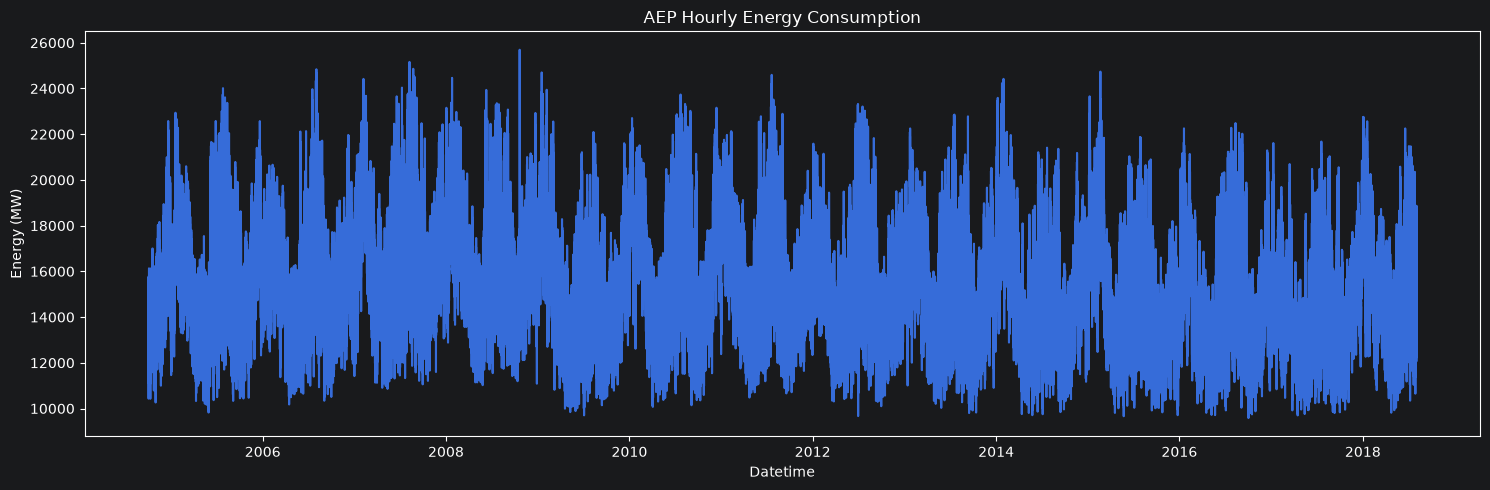

count    121269.000000
mean      15499.651721
std        2591.323421
min        9581.000000
25%       13630.000000
50%       15310.000000
75%       17200.000000
max       25695.000000
Name: Energy_MW, dtype: float64


In [4]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["Energy_MW"])
plt.title("AEP Hourly Energy Consumption")
plt.xlabel("Datetime")
plt.ylabel("Energy (MW)")
plt.tight_layout()
plt.show()

print(df["Energy_MW"].describe())


## 4. Feature engineering

Features include calendar variables, cyclic time encodings, historical lags, and leakage-safe rolling statistics. Rolling statistics are calculated from `shift(1)` so the current target is never included in its own predictors.

In [5]:
def make_features(df):
    x = df.copy()
    idx = x.index

    x["hour"] = idx.hour
    x["dayofweek"] = idx.dayofweek
    x["dayofmonth"] = idx.day
    x["dayofyear"] = idx.dayofyear
    x["weekofyear"] = idx.isocalendar().week.astype(int)
    x["month"] = idx.month
    x["quarter"] = idx.quarter
    x["year"] = idx.year
    x["is_weekend"] = (idx.dayofweek >= 5).astype(int)

    x["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    x["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    x["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    x["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    x["month_sin"] = np.sin(2 * np.pi * idx.month / 12)
    x["month_cos"] = np.cos(2 * np.pi * idx.month / 12)

    for lag in LAGS:
        x[f"lag_{lag}"] = x["Energy_MW"].shift(lag)

    shifted = x["Energy_MW"].shift(1)
    for window in ROLLING_WINDOWS:
        x[f"rolling_mean_{window}"] = shifted.rolling(window).mean()
        x[f"rolling_std_{window}"] = shifted.rolling(window).std()
        x[f"rolling_min_{window}"] = shifted.rolling(window).min()
        x[f"rolling_max_{window}"] = shifted.rolling(window).max()

    return x.dropna()

feat = make_features(df)
feature_cols = [c for c in feat.columns if c != "Energy_MW"]
feat.shape, len(feature_cols)


((121101, 31), 30)

## 5. Chronological train/test split

Random shuffling is intentionally avoided. The final 20% of observations form the unseen test period.

In [6]:
split_idx = int(len(feat) * 0.80)
train = feat.iloc[:split_idx]
test = feat.iloc[split_idx:]

X_train, y_train = train[feature_cols], train["Energy_MW"]
X_test, y_test = test[feature_cols], test["Energy_MW"]

print("Train:", train.index.min(), "to", train.index.max(), len(train))
print("Test :", test.index.min(), "to", test.index.max(), len(test))


Train: 2004-10-08 01:00:00 to 2015-10-28 16:00:00 96880
Test : 2015-10-28 17:00:00 to 2018-08-03 00:00:00 24221


## 6. Baseline: weekly seasonal naive

For each test timestamp, predict the value from 168 hours earlier. This gives a simple benchmark for weekly seasonality.

In [7]:
baseline_pred = test["lag_168"].values

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def score(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_metrics = score(y_test, baseline_pred)
baseline_metrics


{'MAE': 1434.4461004913092,
 'RMSE': np.float64(1908.5367035421662),
 'R2': 0.3908038320309859}

## 7. XGBoost model

In [8]:
model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
pred = model.predict(X_test)

xgb_metrics = score(y_test, pred)
results = pd.DataFrame([baseline_metrics, xgb_metrics],
                       index=["Seasonal_Naive_168h", "XGBoost"])
results


,MAE,RMSE,R2
Seasonal_Naive_168h,1434.446100,1908.536704,0.390804
XGBoost,108.321999,146.533853,0.996409


## 8. Evaluation: actual vs predicted

                          MAE      RMSE     R2
Seasonal_Naive_168h  1434.446  1908.537  0.391
XGBoost               108.322   146.534  0.996


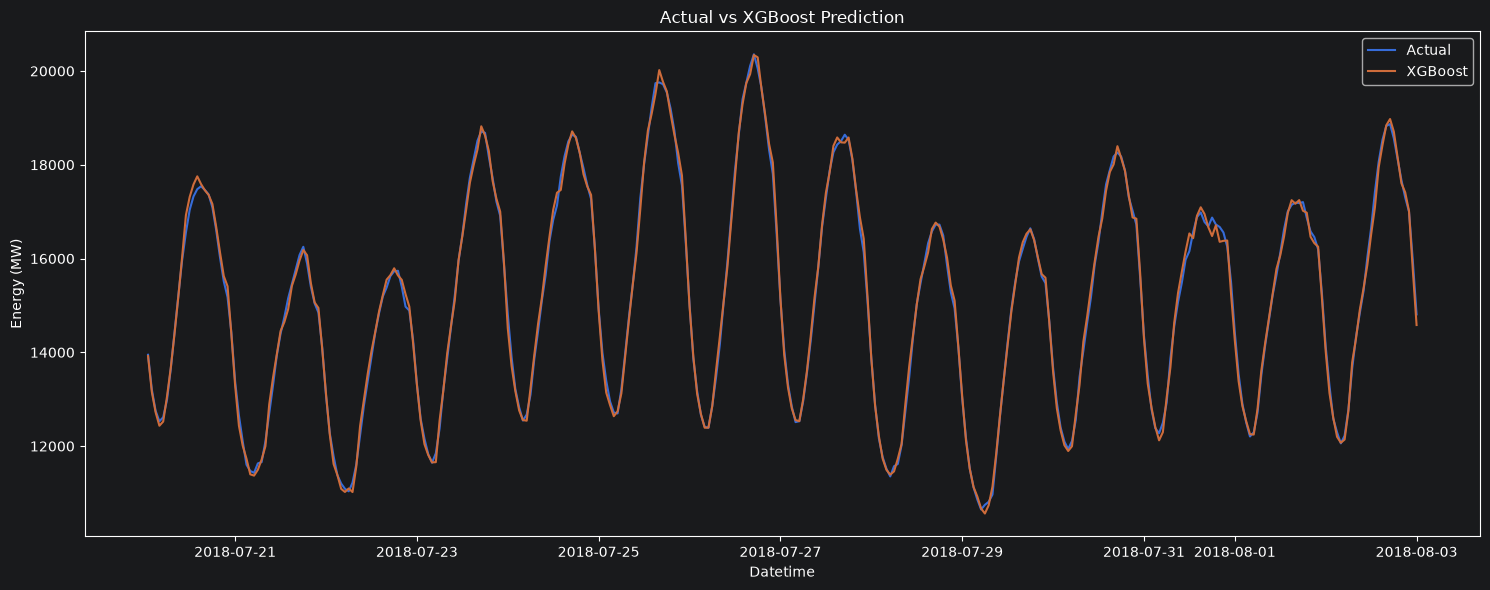

In [9]:
print(results.round(3))

plot_n = min(24 * 14, len(test))
plt.figure(figsize=(15, 6))
plt.plot(test.index[-plot_n:], y_test.iloc[-plot_n:], label="Actual")
plt.plot(test.index[-plot_n:], pred[-plot_n:], label="XGBoost")
plt.title("Actual vs XGBoost Prediction")
plt.xlabel("Datetime")
plt.ylabel("Energy (MW)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=180)
plt.show()


## 9. Feature importance

,importance
lag_1,0.667901
lag_2,0.198679
hour_cos,0.037400
lag_168,0.015458
lag_24,0.013646
hour,0.013249
is_weekend,0.008590
rolling_max_24,0.006695
month_cos,0.006546
lag_3,0.005916


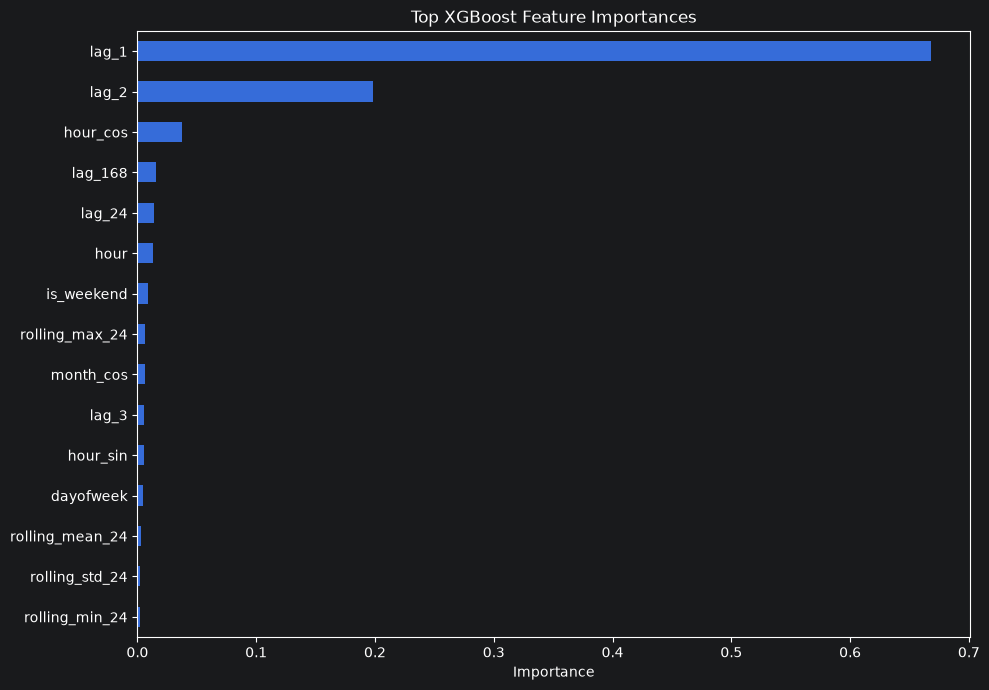

In [10]:
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
display(importance.head(20).to_frame("importance"))

plt.figure(figsize=(10, 7))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=180)
plt.show()


## 10. Recursive next-24-hour forecast

The future target is unknown, so each predicted hour is fed back into the history before creating the next hour's lag/rolling features.

                      Forecast_MW
Datetime                         
2018-08-03 01:00:00  13639.890625
2018-08-03 02:00:00  12918.429688
2018-08-03 03:00:00  12450.309570
2018-08-03 04:00:00  12183.596680
2018-08-03 05:00:00  12182.461914
2018-08-03 06:00:00  12620.387695
2018-08-03 07:00:00  13513.284180
2018-08-03 08:00:00  14206.144531
2018-08-03 09:00:00  14860.487305
2018-08-03 10:00:00  15507.417969
2018-08-03 11:00:00  16243.127930
2018-08-03 12:00:00  16967.402344
2018-08-03 13:00:00  17662.373047
2018-08-03 14:00:00  18167.623047
2018-08-03 15:00:00  18450.710938
2018-08-03 16:00:00  18564.482422
2018-08-03 17:00:00  18723.000000
2018-08-03 18:00:00  18535.335938
2018-08-03 19:00:00  18034.310547
2018-08-03 20:00:00  17422.513672
2018-08-03 21:00:00  16998.253906
2018-08-03 22:00:00  16739.419922
2018-08-03 23:00:00  15682.443359
2018-08-04 00:00:00  14349.900391


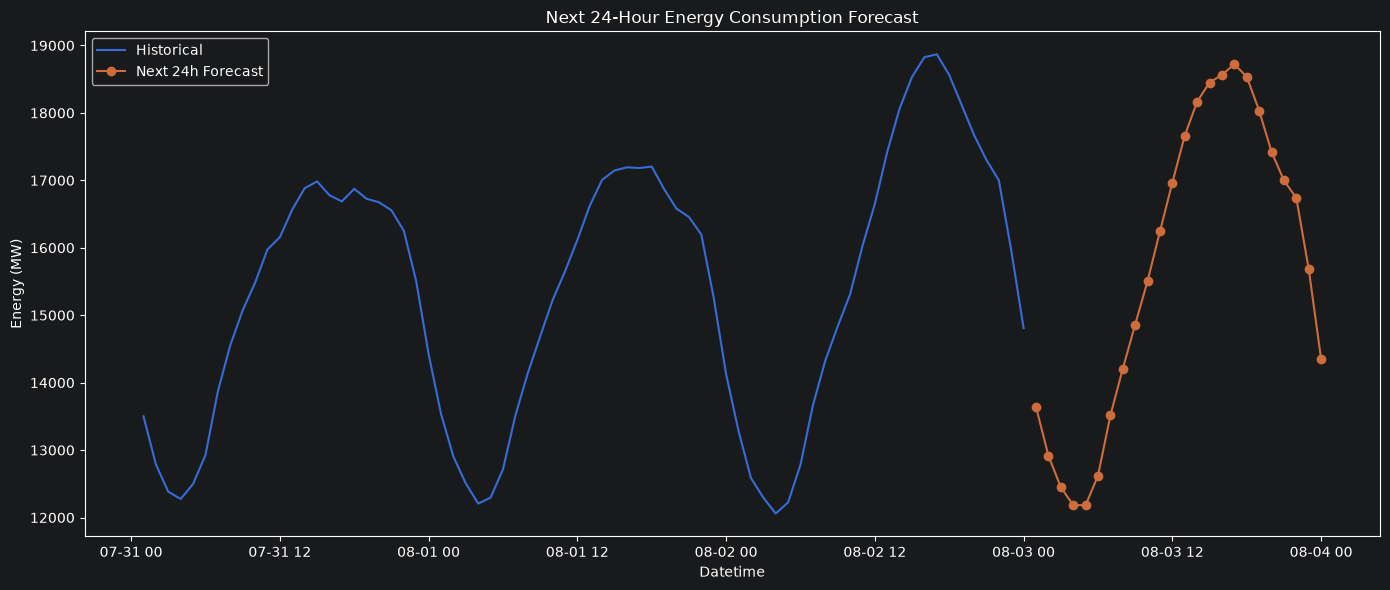

In [11]:
history = df[["Energy_MW"]].copy()

future_rows = []

for _ in range(24):
    next_ts = history.index.max() + pd.Timedelta(hours=1)

    temp = pd.concat([
        history,
        pd.DataFrame(
            {"Energy_MW": [0.0]},
            index=[next_ts]
        )
    ])

    engineered = make_features(temp)

    row = engineered.loc[[next_ts], feature_cols]

    yhat = float(model.predict(row)[0])

    future_rows.append({
        "Datetime": next_ts,
        "Forecast_MW": yhat
    })

    history.loc[next_ts, "Energy_MW"] = yhat

future_forecast = pd.DataFrame(future_rows)

future_forecast["Datetime"] = pd.to_datetime(
    future_forecast["Datetime"]
)

future_forecast = future_forecast.set_index("Datetime")

print(future_forecast)

plt.figure(figsize=(14, 6))

plt.plot(
    df.index[-72:],
    df["Energy_MW"].iloc[-72:],
    label="Historical"
)

plt.plot(
    future_forecast.index,
    future_forecast["Forecast_MW"],
    marker="o",
    label="Next 24h Forecast"
)

plt.title("Next 24-Hour Energy Consumption Forecast")
plt.xlabel("Datetime")
plt.ylabel("Energy (MW)")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "next_24h_forecast.png",
    dpi=180
)

plt.show()


## 11. Save results and model

In [12]:
import joblib

results.to_csv(OUTPUT_DIR / "metrics.csv")
importance.head(20).to_csv(OUTPUT_DIR / "feature_importance_top20.csv", header=["importance"])
future_forecast.to_csv(OUTPUT_DIR / "next_24h_forecast.csv")
joblib.dump({"model": model, "features": feature_cols}, OUTPUT_DIR / "xgboost_energy_model.joblib")

print("Saved:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p)


Saved:
 - outputs\actual_vs_predicted.png
 - outputs\feature_importance.png
 - outputs\feature_importance_top20.csv
 - outputs\metrics.csv
 - outputs\next_24h_forecast.csv
 - outputs\next_24h_forecast.png
 - outputs\xgboost_energy_model.joblib


## 12. Interpretation

- The XGBoost model learns nonlinear relationships among calendar, lag, and rolling features.
- The 168-hour lag provides a direct weekly-seasonality reference.
- MAE measures average absolute error in MW; RMSE penalizes larger errors more strongly; R² measures explained variance.
- The model's feature-importance ranking provides an interpretable view of which engineered predictors contributed most to the fitted tree ensemble.

**Do not copy the generated metric values into the presentation until the notebook has been run on the final dataset version.**